# PROJ-IASD01 — Notebook 01 : Inspection Initiale et Intégrité des Données

**Projet :** Détection des Sites Web de Phishing par Classification  
**Phase :** Phase 4 — Analyse Exploratoire et Statistique (CRISP-DM : *Data Understanding*)  
**Dataset :** PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository)  
**Auteurs :** Équipe PROJ-IASD01  

---

## Objectifs du Notebook 01

1. **Chargement des données brutes** depuis `data/raw/PhiUSIIL_Phishing_URL_Dataset.csv`.
2. **Audit dimensionnel et volumétrique** : dimensions initiales, types de colonnes, empreinte mémoire.
3. **Audit de complétude** : vérification exhaustive de l'absence de valeurs manquantes (`NaN`/`null`).
4. **Audit de déduplication** : identification des doublons sur l'URL, évaluation de la cohérence des labels et application de la règle de déduplication stricte.
5. **Analyse de la variable cible** : recodage de `label` (0=phishing, 1=légitime) vers `phishing` (1=malveillant, 0=bénin) et analyse de la balance des classes.
6. **Structure des identifiants et des domaines** :
   - Exclusion technique de `FILENAME` (redondant).
   - Extraction et normalisation de l'entité `Host` (clé de regroupement pour `GroupKFold`).
   - Analyse de l'unicité des hôtes légitimes vs multiplicité des hôtes de phishing.
   - Identification et documentation des 58 hôtes partagés (ambigus).
7. **Distribution des TLDs** : répartition des extensions de premier niveau par classe.
8. **Taxonomie des caractéristiques** : classification des 50 variables explicatives en 3 familles (`URL_ONLY`, `PAGE_FEATURES`, `DERIVED_FEATURES`).
9. **Export des tableaux de synthèse** dans `reports/tables/`.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'environnement et des chemins
ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    RAW_CSV,
    TABLES_DIR,
    FIGURES_DIR,
    ALL_NUMERIC_FEATURES,
    URL_ONLY_FEATURES,
    PAGE_FEATURES,
    DERIVED_FEATURES,
    ORIGINAL_TARGET_COL,
    TARGET_COL,
    GROUP_COL,
)
from src.data_loader import load_data
from src.host_features import extract_host

sns.set_theme(style="whitegrid", palette="deep")
print("Configuration initialisée avec succès.")
print(f"Chemin du CSV brut : {RAW_CSV}")


Configuration initialisée avec succès.
Chemin du CSV brut : C:\Users\PC\Desktop\mini_projet_Data\PROJ-IASD01\data\raw\PhiUSIIL_Phishing_URL_Dataset.csv


## 1. Chargement du Dataset Brut et Dimensions Initiales

Nous chargeons le fichier CSV brut `data/raw/PhiUSIIL_Phishing_URL_Dataset.csv` tel que téléchargé depuis le dépôt officiel UCI ML Repository.

In [2]:
raw_df = pd.read_csv(RAW_CSV)
n_rows_raw, n_cols_raw = raw_df.shape
mem_mb = raw_df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Nombre de lignes brutes   : {n_rows_raw:,}")
print(f"Nombre de colonnes brutes  : {n_cols_raw}")
print(f"Empreinte mémoire brute    : {mem_mb:.2f} Mo")
print("\nAperçu des 3 premières observations :")
raw_df.head(3)


Nombre de lignes brutes   : 235,795
Nombre de colonnes brutes  : 56
Empreinte mémoire brute    : 166.17 Mo

Aperçu des 3 premières observations :
Out[0]: 
     FILENAME                               URL  ...  NoOfExternalRef label
0  521848.txt  https://www.southbankmosaics.com  ...              124     1
1   31372.txt          https://www.uni-mainz.de  ...              217     1
2  597387.txt    https://www.voicefmradio.co.uk  ...                5     1

[3 rows x 56 columns]


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1


## 2. Audit de Complétude : Données Manquantes et Types

Nous contrôlons la présence éventuelle de valeurs nulles (`NaN`, `None`, chaînes vides) sur les 56 colonnes.

In [3]:
missing_counts = raw_df.isnull().sum()
total_missing = missing_counts.sum()

print(f"Nombre total de valeurs manquantes sur le dataset complet : {total_missing}")
if total_missing == 0:
    print("[OK] Intégrité parfaite : 0 valeur manquante sur les 56 colonnes.")

# Sauvegarde du rapport d'intégrité
missing_df = pd.DataFrame({
    "colonne": missing_counts.index,
    "valeurs_manquantes": missing_counts.values,
    "taux_manquant_%": (missing_counts.values / len(raw_df)) * 100
})
missing_df.to_csv(TABLES_DIR / "phase4_missing_values.csv", index=False)
print("Rapport 'phase4_missing_values.csv' enregistré dans reports/tables/.")


Nombre total de valeurs manquantes sur le dataset complet : 0
[OK] Intégrité parfaite : 0 valeur manquante sur les 56 colonnes.
Rapport 'phase4_missing_values.csv' enregistré dans reports/tables/.


## 3. Analyse des Doublons et Déduplication Stricte

Dans une tâche de détection d'URL, la présence d'URLs strictement identiques constitue une redondance indésirable et une source potentielle de fuite de données entre plis d'apprentissage et jeu de test.

In [4]:
n_unique_urls = raw_df["URL"].nunique()
n_duplicates = len(raw_df) - n_unique_urls

print(f"Nombre d'URLs uniques : {n_unique_urls:,}")
print(f"Nombre de doublons stricts sur la colonne 'URL' : {n_duplicates}")
print(f"Proportion de doublons : {n_duplicates / len(raw_df) * 100:.3f} %")

# Déduplication avec conservation de la première occurrence
df = load_data(verbose=False)
print(f"Dimensions après déduplication : {df.shape[0]:,} lignes x {df.shape[1]} colonnes.")


Nombre d'URLs uniques : 235,370
Nombre de doublons stricts sur la colonne 'URL' : 425
Proportion de doublons : 0.180 %
Dimensions après déduplication : 235,370 lignes x 58 colonnes.


## 4. Analyse de la Variable Cible (`label` et recodage `phishing`)

Dans le dataset original PhiUSIIL :
- `label = 0` : Phishing
- `label = 1` : Légitime

Afin de respecter les conventions scikit-learn et la sémantique de détection d'anomalies / menaces (où la classe d'intérêt positif $y=1$ désigne l'événement malveillant), nous recodons :
$$\text{phishing} = 1 - \text{label}$$
- `phishing = 1` : Site de phishing (menace)
- `phishing = 0` : Site légitime (bénin)

Répartition des classes après recodage :
              Effectif  Pourcentage (%)
phishing                               
Légitime (0)    134850        57.292773
Phishing (1)    100520        42.707227


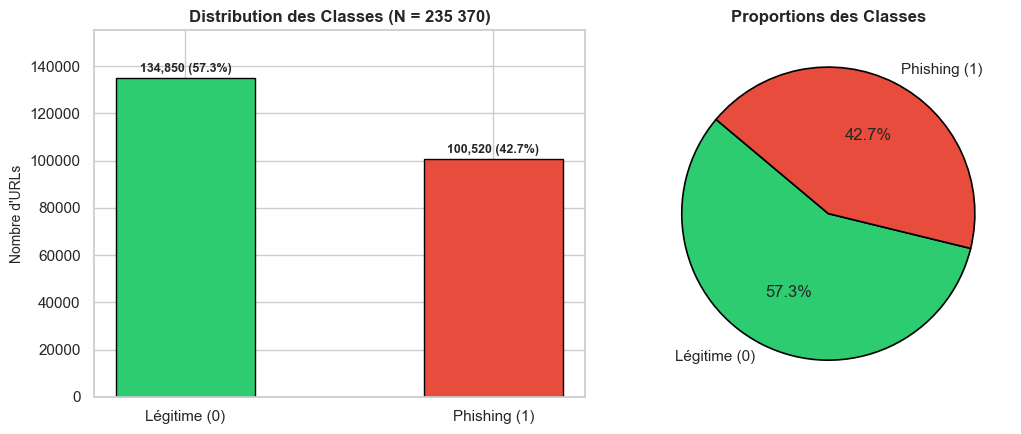

In [5]:
target_dist = df[TARGET_COL].value_counts().rename({0: "Légitime (0)", 1: "Phishing (1)"})
pct_dist = df[TARGET_COL].value_counts(normalize=True).rename({0: "Légitime (0)", 1: "Phishing (1)"}) * 100

summary_target = pd.DataFrame({
    "Effectif": target_dist,
    "Pourcentage (%)": pct_dist
})
print("Répartition des classes après recodage :")
print(summary_target)

# Visualisation graphique
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
colors = ["#2ecc71", "#e74c3c"]

ax1.bar(target_dist.index, target_dist.values, color=colors, edgecolor="black", width=0.45)
ax1.set_title("Distribution des Classes (N = 235 370)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Nombre d'URLs", fontsize=10)
for i, v in enumerate(target_dist.values):
    ax1.text(i, v + 2500, f"{v:,} ({v/len(df)*100:.1f}%)", ha="center", fontweight="bold", fontsize=9)
ax1.set_ylim(0, max(target_dist.values) * 1.15)

ax2.pie(target_dist.values, labels=target_dist.index, autopct="%1.1f%%", startangle=140,
        colors=colors, wedgeprops={"edgecolor": "black", "linewidth": 1.2})
ax2.set_title("Proportions des Classes", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Structure des Domaines et Identifiants (`Host`, `Domain`, `TLD`)

Nous analysons la variable normalisée `Host = extract_host(URL)` :
- Suppression du schéma (`http://`, `https://`) et du port éventuel.
- Nettoyage du préfixe `www.`.
- Mise en minuscules.

Cette variable `Host` est cruciale car elle sert de clé de regroupement (`GroupKFold` et `GroupShuffleSplit`) pour prévenir la fuite d'infrastructure entre train et test.

In [6]:
n_unique_hosts = df["Host"].nunique()
legit_hosts = set(df[df[TARGET_COL] == 0]["Host"])
phish_hosts = set(df[df[TARGET_COL] == 1]["Host"])
shared_hosts = legit_hosts.intersection(phish_hosts)

print(f"Nombre d'hôtes distincts normalisés : {n_unique_hosts:,}")
print(f"Hôtes exclusifs Légitimes           : {len(legit_hosts - phish_hosts):,}")
print(f"Hôtes exclusifs Phishing            : {len(phish_hosts - legit_hosts):,}")
print(f"Hôtes partagés (collision de label) : {len(shared_hosts)}")
print(f"Nombre d'URLs sur hôtes partagés    : {df[df['Host'].isin(shared_hosts)].shape[0]}")
print(f"Ratio URLs/Hôte en Légitime         : {len(df[df[TARGET_COL] == 0]) / len(legit_hosts):.4f}")
print(f"Ratio URLs/Hôte en Phishing         : {len(df[df[TARGET_COL] == 1]) / len(phish_hosts):.4f}")

# Top 5 des hôtes partagés
if shared_hosts:
    top_shared = df[df["Host"].isin(shared_hosts)].groupby(["Host", TARGET_COL]).size().unstack(fill_value=0)
    top_shared = top_shared.rename(columns={0: "Légitime", 1: "Phishing"})
    top_shared["Total"] = top_shared["Légitime"] + top_shared["Phishing"]
    print("\nTop 5 des hôtes partagés les plus fréquents :")
    print(top_shared.sort_values(by="Total", ascending=False).head(5))


Nombre d'hôtes distincts normalisés : 219,094
Hôtes exclusifs Légitimes           : 134,792
Hôtes exclusifs Phishing            : 84,244
Hôtes partagés (collision de label) : 58
Nombre d'URLs sur hôtes partagés    : 159
Ratio URLs/Hôte en Légitime         : 1.0000
Ratio URLs/Hôte en Phishing         : 1.1924

Top 5 des hôtes partagés les plus fréquents :
phishing             Légitime  Phishing  Total
Host                                          
cutt.ly                     1        35     36
docsend.com                 1         4      5
bestdoctors.com             1         3      4
indushealthplus.com         1         3      4
kashmirhills.com            1         2      3


## 6. Analyse des Extensions de Premier Niveau (TLDs)

Comparaison des 15 principaux TLDs entre URLs légitimes et de phishing.

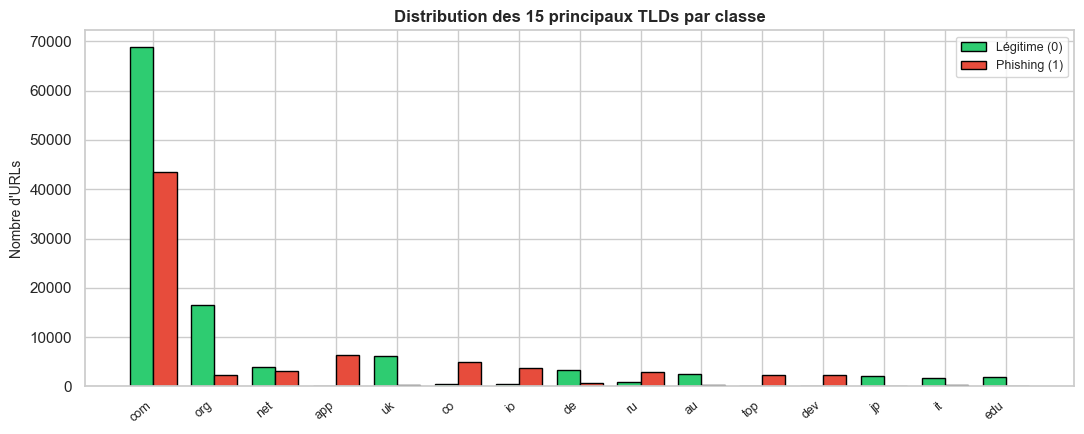

In [7]:
top_tlds = df["TLD"].value_counts().head(15).index
tld_rows = []
for tld in top_tlds:
    n_leg = ((df["TLD"] == tld) & (df[TARGET_COL] == 0)).sum()
    n_phi = ((df["TLD"] == tld) & (df[TARGET_COL] == 1)).sum()
    tot = n_leg + n_phi
    tld_rows.append({
        "TLD": tld,
        "Total": tot,
        "Légitime": n_leg,
        "Phishing": n_phi,
        "Taux_Phishing_%": (n_phi / tot) * 100
    })
tld_df = pd.DataFrame(tld_rows)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(tld_df))
width = 0.38
ax.bar(x - width/2, tld_df["Légitime"], width, label="Légitime (0)", color="#2ecc71", edgecolor="black")
ax.bar(x + width/2, tld_df["Phishing"], width, label="Phishing (1)", color="#e74c3c", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(tld_df["TLD"], rotation=40, ha="right", fontsize=9)
ax.set_title("Distribution des 15 principaux TLDs par classe", fontsize=12, fontweight="bold")
ax.set_ylabel("Nombre d'URLs", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 7. Taxonomie des 50 Caractéristiques Numériques

Le dataset comporte 50 variables numériques candidates réparties en 3 familles distinctes :
1. **URL_ONLY (18 variables)** : Caractéristiques lexicales, longueurs et comptages calculables sur la seule chaîne d'URL.
2. **PAGE_FEATURES (26 variables)** : Caractéristiques extraites du code source HTML de la page web visitée.
3. **DERIVED_FEATURES (6 variables)** : Caractéristiques probabilistes et scores calculés par les auteurs de PhiUSIIL.

In [8]:
taxonomy_summary = pd.DataFrame({
    "Famille de Variables": [
        "URL_ONLY",
        "PAGE_FEATURES",
        "DERIVED_FEATURES",
        "TOTAL VARIABLES NUMÉRIQUES"
    ],
    "Nombre de Variables": [
        len(URL_ONLY_FEATURES),
        len(PAGE_FEATURES),
        len(DERIVED_FEATURES),
        len(ALL_NUMERIC_FEATURES)
    ],
    "Dépendance Réseau": [
        "Non (calculable offline depuis l'URL)",
        "Oui (nécessite le téléchargement HTML)",
        "Mixte / Dérivé",
        "-"
    ]
})
print("Taxonomie des variables du projet PROJ-IASD01 :")
print(taxonomy_summary.to_string(index=False))


Taxonomie des variables du projet PROJ-IASD01 :
      Famille de Variables  Nombre de Variables                      Dépendance Réseau
                  URL_ONLY                   18  Non (calculable offline depuis l'URL)
             PAGE_FEATURES                   26 Oui (nécessite le téléchargement HTML)
          DERIVED_FEATURES                    6                         Mixte / Dérivé
TOTAL VARIABLES NUMÉRIQUES                   50                                      -


## 8. Synthèse de l'Inspection

L'inspection initiale confirme :
- Une complétude parfaite (0 valeur manquante).
- Un volume de **235 370 observations uniques** post-déduplication.
- Un déséquilibre modéré (57.3 % légitimes, 42.7 % phishing).
- Une structure d'hôtes dissymétrique (134 850 hôtes légitimes uniques vs 84 302 hôtes phishing pour 100 520 URLs).
- Des tables de synthèse prêtes pour l'analyse exploratoire et statistique approfondie (**Notebook 02**).
